In [ ]:
import torch 
import torch.nn as nn
import torch.nn.functional as F
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
from PIL import Image

In [10]:
batch_size = 60

train_dataset = datasets.MNIST(root="dataset/", download=True, train=True, transform=transforms.ToTensor())

train_loader = DataLoader(dataset=train_dataset, batch_size=batch_size, shuffle=True)

test_dataset = datasets.MNIST(root="dataset/", download=True, train=False, transform=transforms.ToTensor())

test_loader = DataLoader(dataset=test_dataset, batch_size=batch_size, shuffle=True)

train_dataset, train_loader, test_dataset, test_loader

(Dataset MNIST
     Number of datapoints: 60000
     Root location: dataset/
     Split: Train
     StandardTransform
 Transform: ToTensor(),
 Dataset MNIST
     Number of datapoints: 10000
     Root location: dataset/
     Split: Test
     StandardTransform
 Transform: ToTensor(),
 <torch.utils.data.dataloader.DataLoader at 0x7c917ffd7820>)

In [11]:
class CNN(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.layers = nn.ModuleList()
        n_layer = 12
        for i in range(n_layer):
            self.layers.append(
                nn.Conv2d(
                    in_channels = in_channels,
                    out_channels = out_channels,
                    kernel_size=3,
                    padding=1
                )
            )
            in_channels = out_channels
        self.fc = nn.Linear(out_channels * 28 * 28, 10)
    
    def forward(self, x):
        for layer in self.layers:
            x = F.relu(layer(x))
        x = x.reshape(x.shape[0], -1)
        x = self.fc(x)

        return x

In [12]:
model = CNN(in_channels=1, out_channels=24)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

In [13]:
model.parameters()

<generator object Module.parameters at 0x7c9180f97140>

In [14]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

In [ ]:
num_epochs = 16
loss_history = []

for epoch in range(num_epochs):
    model.train()
    total_loss = 0.0

    for images, labels in train_loader:
        optimizer.zero_grad()

        # Predict
        predictions = model(images)

        # Calculate loss
        loss = criterion(predictions, labels)

        # Compute gradients
        loss.backward()

        # Update weights
        optimizer.step()

        total_loss += loss.item()

    avg_loss = total_loss / len(train_loader)
    loss_history.append(avg_loss)

    print(f"Epoch [{epoch + 1}/{num_epochs}], Loss: {avg_loss:.4f}")


plt.plot(range(1, num_epochs + 1), loss_history, marker="o")
plt.xlabel("Epoch")
plt.ylabel("Average Loss")
plt.title("Training Loss Over Epochs")
plt.xticks(range(1, num_epochs + 1))
plt.grid(True)
plt.show()

In [ ]:
model.eval()

CNN(
  (layers): ModuleList(
    (0): Conv2d(1, 24, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1-11): 11 x Conv2d(24, 24, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  )
  (fc): Linear(in_features=18816, out_features=10, bias=True)
)

In [ ]:
correct = 0
total = 0

Test Accuracy: 100.00%


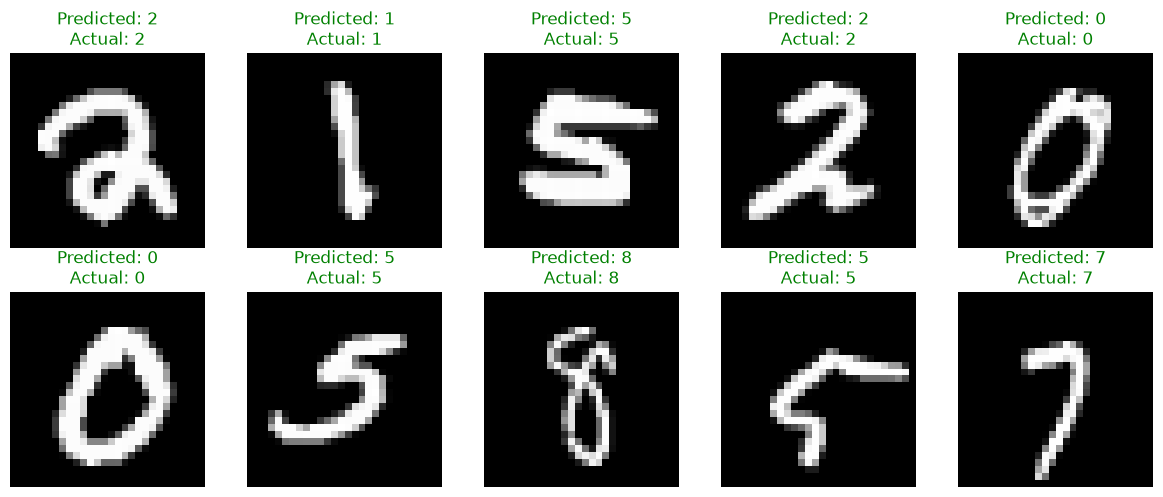

In [ ]:
def evaluate_and_visualize(model, test_loader, device):
    model.eval()
    correct = 0
    total = 0

    images_to_show = []
    actual_labels = []
    predicted_labels_list = []

    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)
            labels = labels.to(device)

            predictions = model(images)
            predicted_labels = predictions.argmax(dim=1)

            total += labels.size(0)
            correct += (predicted_labels == labels).sum().item()

            for i in range(min(len(images), 10 - len(images_to_show))):
                images_to_show.append(images[i].detach().cpu().squeeze())
                actual_labels.append(labels[i].item())
                predicted_labels_list.append(predicted_labels[i].item())

            if len(images_to_show) >= 10:
                break

    print(f"Test Accuracy: {100 * correct / total:.2f}%")

    _fig, axes = plt.subplots(2, 5, figsize=(12, 5))

    for i, ax in enumerate(axes.flat):
        ax.imshow(images_to_show[i], cmap="gray")
        ax.set_title(
            f"Predicted: {predicted_labels_list[i]}\n"
            f"Actual: {actual_labels[i]}",
            color="green" if predicted_labels_list[i] == actual_labels[i] else "red"
        )
        ax.axis("off")

    plt.tight_layout()
    plt.show()
evaluate_and_visualize(model, test_loader, device)

In [ ]:
def predict_custom_image(model, image_path):
    model.eval()
    device = next(model.parameters()).device

    transform = transforms.Compose([
        transforms.Grayscale(num_output_channels=1),
        transforms.Resize((28, 28)),
        transforms.ToTensor()
    ])

    image = Image.open(image_path).convert("RGB")
    image_tensor = transform(image).unsqueeze(0).to(device)

    with torch.no_grad():
        predictions = model(image_tensor)
        predicted_digit = predictions.argmax(dim=1).item()

    plt.imshow(image_tensor.cpu().squeeze(), cmap="gray")
    plt.title(f"Predicted digit: {predicted_digit}")
    plt.axis("off")
    plt.show()

    return predicted_digit

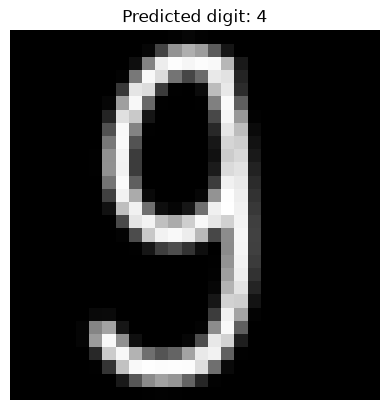

In [ ]:
image_path = "/home/aks/vs_stuff/Development/ai_devs/cnn/image.png"

prediction = predict_custom_image(model, image_path)